In [1]:
!pip3.10 install matplotlib

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: /usr/bin/python3 -m pip install --upgrade pip


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import glob
import re
from collections import defaultdict, Counter
import requests

import xml.etree.ElementTree as ET
import time
import random

sns.set_theme(rc={'figure.figsize':(11.7,8.27)})

metadata = pd.read_csv("./metadata.csv")
metadata_monographie = pd.read_csv("./data_mono.csv", header=None, names=["type", "ark", "titre", "date", "auteur", "langue"], sep=";", usecols=range(6))

datacat = pd.read_csv("./catalogs_subset_stats (1).csv", names=["ark", "filename", "year", "folio"])

datacat.filename = datacat.filename.apply(lambda x: (re.findall("(12148_[a-z0-9]+)_", x) or [x])[0])

In [3]:


HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/120.0 Safari/537.36",
    "Accept": "application/xml,text/xml;q=0.9,*/*;q=0.8",
    "Connection": "keep-alive",
}

def fetch_gallica_date(ark_id, max_retries=4, base_delay=2):
    url = f"https://gallica.bnf.fr/services/OAIRecord?ark={ark_id}"

    for attempt in range(max_retries):
        try:
            response = requests.get(url, headers=HEADERS, timeout=10)
            response.raise_for_status()

            root = ET.fromstring(response.content)

            ns = {
                "dc": "http://purl.org/dc/elements/1.1/",
                "oai_dc": "http://www.openarchives.org/OAI/2.0/oai_dc/"
            }

            date_elem = root.find(".//dc:date", ns)
            return date_elem.text if date_elem is not None else None

        except requests.RequestException as e:
            print(f"Attempt {attempt+1} failed: {e}")

            delay = base_delay * (2 ** attempt) + random.uniform(0, 1)
            print(f"Waiting {delay:.2f}s...")
            time.sleep(delay)

    return None

In [4]:
def clean_date(date):
    if pd.isna(date):
        return None
    if isinstance(date, float):
        date=int(date)
    date = str(date).strip()
    date = date.replace("_", "")
    
    if len(date) == 2:
        date = date + "00"
    elif len(date) == 3:
        date = date + "0"
    elif len(date) >= 4:
        double_date = re.search(r'(\d{4})-(\d{4})', date)
        if double_date:
            date = double_date.group(1)
        date = date.replace(".", "").replace("?", "")
    
    date = date.replace(".", "0").replace("?", "0")
    
    if not date.isdigit():
        return None
    
    return int(date)

In [5]:
subsets = defaultdict(list)
re_gallica = re.compile(r"(b[dp]+[A_Za-z0-9]+)_[f]?(\d+)_jp[e]?g")
re_bpt = re.compile(r"((?:bpt6|bd6t|cb)[a-z0-9]+)_")
re_persee = re.compile(r"^[^_]+_[^_]+_(\d{4})_(?:[a-z]{3})_")
n=0
for file in glob.glob("../LADAS2-REVIEW-act/*/*/*.jpg"):
    _, _, split, subset, filename = file.split("/")
    if "test" in subset: 
        subset_clean = subset.replace("-test", "")
    elif "train" in subset:
        subset_clean = subset.replace("-train", "")
    elif "valid" in subset:
        subset_clean = subset.replace("-valid", "")
    simpler_subset = { "administrative-reports": "Admin", 
                           "roman-19": "Romans19", 
                           "picard": "Others", 
                           "typewriter": "Others", 
                           "magazine-tech": "Tech. Magazines", 
                           "persee": "Persée", 
                           "these": "These", 
                           "catalogue": "Catalogue", 
                           "theatre": "Theatre", 
                           "monographies": "Monographs"}.get(subset_clean, "Others") 
    if "catalogue" in subset:
        line_metadata_cat = datacat[datacat["filename"]==filename]
        if line_metadata_cat.empty:
            ark = re_bpt.findall(filename)
            if ark:
                line_metadata_gallica = metadata_monographie[metadata_monographie["ark"]==ark[0]]
                if line_metadata_gallica.empty:
                    if ark[0].startswith("bpt6k"):
                        date = fetch_gallica_date(ark[0])
                        subsets[subset].append((filename, clean_date(date), simpler_subset))
                    else:
                        print(filename)
                        n+=1
                elif pd.isna(line_metadata_gallica['date']).all():
                    if ark[0].startswith("bpt6k"):
                        date = fetch_gallica_date(ark[0])
                        subsets[subset].append((filename, clean_date(date), simpler_subset))
                    else:
                        print(filename)
                        n+=1
                else: 
                    date = line_metadata_gallica['date'].iloc[0]
                    subsets[subset].append((filename, clean_date(date), simpler_subset))
            else:
                print(filename)
                n+=1
        else: 
            date = line_metadata_cat['year'].iloc[0]
            subsets[subset].append((filename, clean_date(date), simpler_subset))
    else:
        try: 
            line_metadata = metadata.loc[filename]
            date = line_metadata['year']
            subsets[subset].append((filename, clean_date(date), simpler_subset)) 
        except KeyError as e: 
            if "dictionnaire" in filename: 
                century = re.search(r'^([0-9]{2})_', filename)
                subsets[subset].append((filename, clean_date(century.group(0)), simpler_subset))
            elif "others" in subset:
                
            elif "persee" in subset: 
                date = re_persee.findall(filename)[0] 
                subsets[subset].append((filename, clean_date(date), simpler_subset)) 
            elif "monographies" in subset or "roman" in subset: 
                date= re.search(r'^([0-9]{4})_', filename)
                if date:
                    subsets[subset].append((filename, clean_date(date.group(0)), simpler_subset)) 
            elif "these" in subset: 
                date= re.search(r'^[0-9]{4}', filename) 
                if date: 
                    subsets[subset].append((filename, clean_date(date.group(0)), simpler_subset)) 
            elif "theatre" in subset or "magazine" in subset or "admin" in subset: 
                date = re.search(r'_([0-9]{4})_', filename)
                ark = re_bpt.findall(filename)
                if date: 
                    subsets[subset].append((filename, clean_date(date.group(0)), simpler_subset)) 
                elif ark: 
                    line_metadata_gallica = metadata_monographie[metadata_monographie["ark"]==ark[0]]
                    date = line_metadata_gallica['date'].iloc[0]
                    subsets[subset].append((filename, clean_date(date), simpler_subset)) 
                else: 
                    n+=1 
                    print(filename) 
            elif "fingers" in subset: 
                subsets[subset].append((filename, 2000, simpler_subset)) 
            else: 
                n+=1 
                print(filename) 
print(subsets)

IndentationError: expected an indented block after 'elif' statement on line 62 (1125190320.py, line 64)

In [6]:
subsets = defaultdict(list)
re_gallica = re.compile(r"(b[dp]+[A_Za-z0-9]+)_[f]?(\d+)_jp[e]?g")
re_bpt = re.compile(r"((?:bpt6|bd6t|cb)[a-z0-9]+)_")
re_persee = re.compile(r"^[^_]+_[^_]+_(\d{4})_(?:[a-z]{3})_")

SUBSET_NAME_MAP = {
    "administrative-reports": "Admin",
    "roman-19": "Romans19",
    "picard": "Others",
    "typewriter": "Others",
    "magazine-tech": "Tech. Magazines",
    "persee": "Persée",
    "these": "These",
    "catalogue": "Catalogue",
    "theatre": "Theatre",
    "monographies": "Monographs",
}

def get_subset_clean(subset):
    for suffix in ("-test", "-train", "-valid"):
        if subset.endswith(suffix):
            return subset[: -len(suffix)]
    return subset

def fetch_date_from_ark(ark):
    """Try to get a date from metadata_monographie or fallback to Gallica API."""
    row = metadata_monographie[metadata_monographie["ark"] == ark]
    if not row.empty and not pd.isna(row["date"]).all():
        return clean_date(row["date"].iloc[0])
    if ark.startswith("bpt6k"):
        return clean_date(fetch_gallica_date(ark))
    return None

n = 0
for file in glob.glob("../LADAS2-REVIEW-act/*/*/*.jpg"):
    print(file)
    _, _, split, subset, filename = file.split("/")
    subset_clean = get_subset_clean(subset)
    simpler_subset = SUBSET_NAME_MAP.get(subset_clean, "Others")

    date = None
    row = metadata[metadata["file"] == filename]
    raw_date = row["year"].iloc[0] if not row.empty else None
    print(raw_date)
    if "catalogue" in subset:
        row = datacat[datacat["filename"] == filename]
        if not row.empty:
            date = clean_date(row["year"].iloc[0])
        else:
            ark = re_bpt.findall(filename)
            if ark:
                date = fetch_date_from_ark(ark[0])
    elif raw_date is not None and not pd.isna(raw_date):
        date = clean_date(raw_date)
    else:
        if "dictionnaire" in filename:
            century = re.search(r"^([0-9]{2})_", filename)
            if century:
                date = clean_date(century.group(0))
        elif "persee" in subset:
            match = re_persee.findall(filename)
            if match:
                date = clean_date(match[0])
        elif "monographies" in subset or "roman" in subset:
            match = re.search(r"^([0-9]{4})_", filename)
            if match:
                date = clean_date(match.group(0))
        elif "these" in subset:
            match = re.search(r"^[0-9]{4}", filename)
            if match:
                date = clean_date(match.group(0))
        elif any(k in subset for k in ("theatre", "magazine", "admin")):
            match = re.search(r"_([0-9]{4})_", filename)
            ark = re_bpt.findall(filename)
            if match:
                date = clean_date(match.group(0))
            elif ark:
                date = fetch_date_from_ark(ark[0])
        elif "fingers" in subset:
            date = 2000

    if date is not None:
        subsets[subset].append((filename, date, simpler_subset))
        print("FOUND"+str(date))
    else:
        n += 1
        print("NOT FOUND"+str(date))

print(subsets)

defaultdict(<class 'list'>, {})


In [ ]:
print(repr(metadata["file"].iloc[1]))
for file in glob.glob("../LADAS2-REVIEW/*/*/*.jpg"):
    _, _, split, subset, filename = file.split("/")
    print(repr(filename))
    break

In [11]:
df = pd.DataFrame([
    (subset, filename, year, simpler_subset)
    for subset, files in subsets.items()
    for filename, year, simpler_subset in files
], columns=["Full Subset", "Filename", "Year", "Subset"])
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
print(df)
df.to_csv("output.csv", index=False)

         Full Subset                                           Filename  Year  \
0     catalogue-test            Lair-Dubreuil_CVP03250_19240411_f15.jpg  1924   
1     catalogue-test                bourgey_12148-bpt6k9778130d_f12.jpg  1958   
2     catalogue-test     bienaime-feuardent_12148-bpt6k9778294p_f44.jpg  1888   
3     catalogue-test                  rollin_12148-bpt6k9777429g_f3.jpg  1859   
4     catalogue-test                rollin_12148-bpt6k9777328q_f124.jpg  1889   
...              ...                                                ...   ...   
8177    persee-train  chana_1111-858x_1950_num_1_1_1165_0059_jpg.rf....  1950   
8178    persee-train  juro_0243-9069_1977_num_1_1_3288_0045_jpg.rf.b...  1977   
8179    persee-train  asdi_1662-4653_2006_num_1_1_858_0068_jpg.rf.c3...  2006   
8180    persee-train  afdi_0066-3085_1955_num_1_1_1146_0085_jpg.rf.f...  1955   
8181    persee-train  piot_1148-6023_1895_num_2_2_1135_0137_jpg.rf.a...  1895   

         Subset  
0     Cat

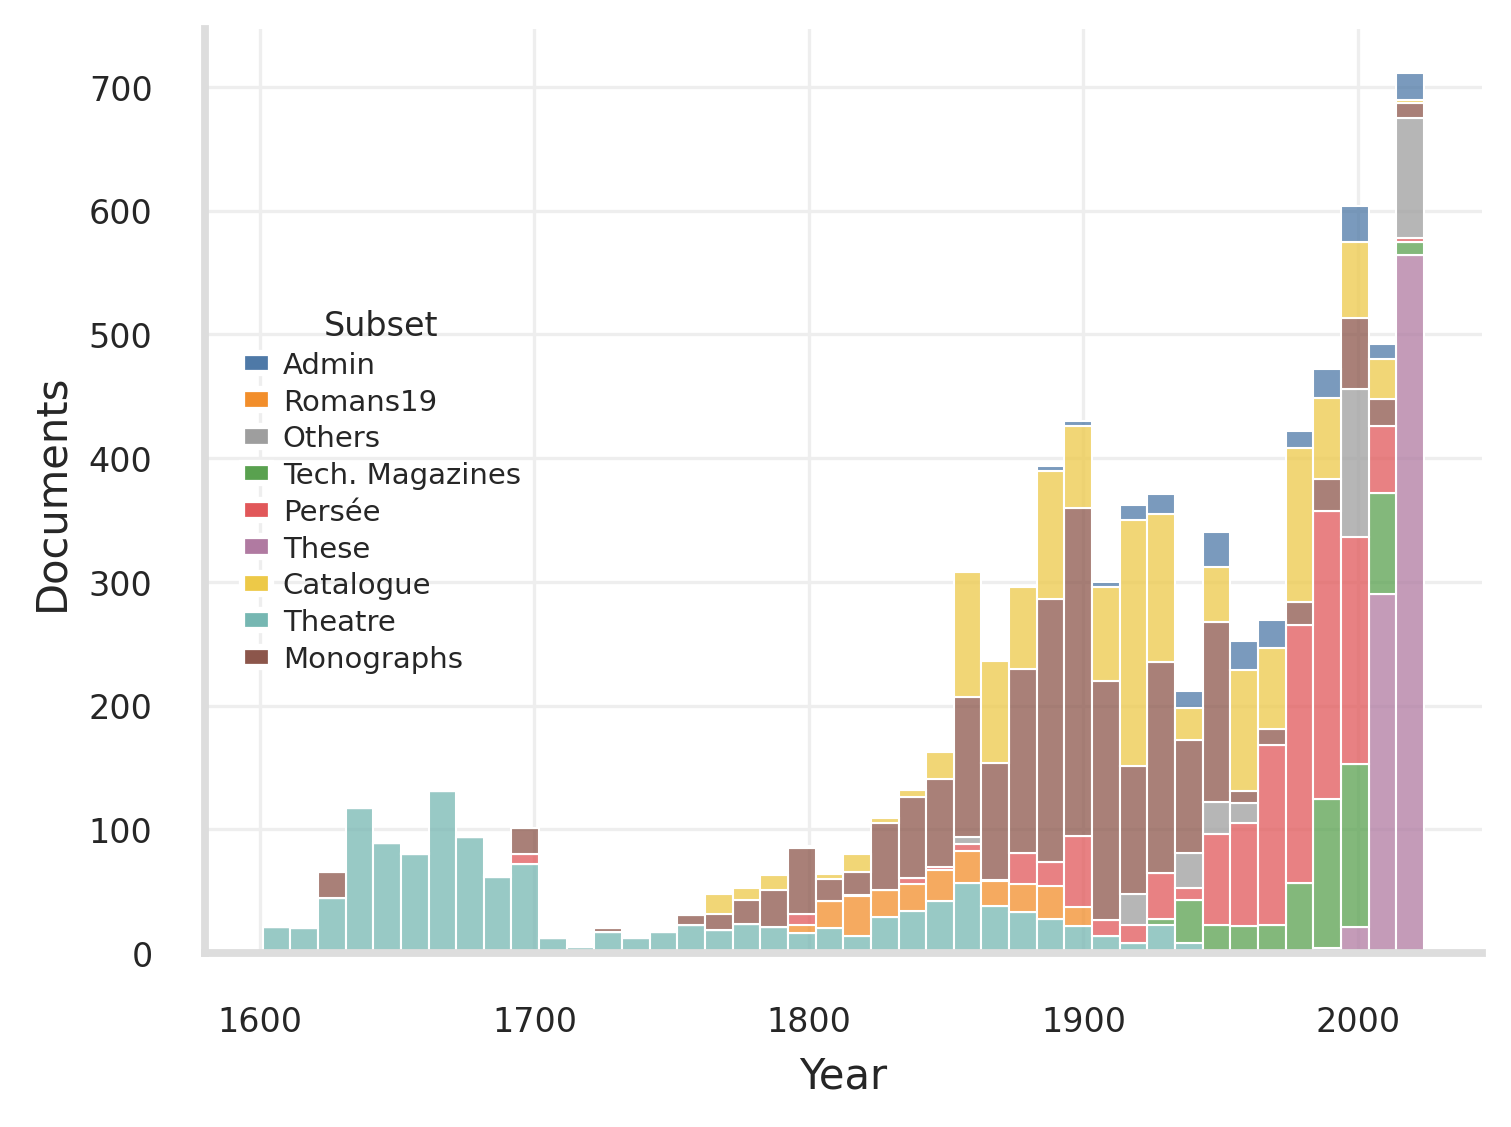

In [127]:
from matplotlib.patches import Patch
sns.set_theme(style="whitegrid", context="talk")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#dddddd",
    "grid.color": "#eeeeee",
    "grid.linewidth": 0.8,
    "axes.titleweight": "bold",
})

fig, ax = plt.subplots(dpi=300, figsize=(6.5, 4))
fig.patch.set_facecolor("white")

sns.histplot(
    data=df[df.Year > 1600].sort_values("Subset"),
    x="Year",
    hue="Subset",
    multiple="stack",
    bins=42,
    palette=palette,
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# ── Labels ─────────────────────────────
ax.set_ylabel("Documents", fontsize=10)
ax.set_xlabel("Year", fontsize=10)

# ── Ticks ──────────────────────────────
ax.tick_params(axis='both', labelsize=8)

# ── Spines ─────────────────────────────
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#dddddd")
ax.spines["bottom"].set_color("#dddddd")

if ax.legend_:
    ax.legend_.remove()
handles = [
    Patch(facecolor=palette[name], label=name)
    for name in palette.keys()
]

ax.legend(
    handles=handles,
    title="Subset",
    fontsize=7,
    title_fontsize=8,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(0.02, 0.5),  # inside, middle-left
    labelspacing=0.3,            # 🔥 tight spacing
    handlelength=1,
    handletextpad=0.4,
    borderaxespad=0
)
# ── Layout (reserve space for legend) ──
plt.subplots_adjust(right=0.78)
plt.savefig('distribution_subsets.png', dpi=300, bbox_inches='tight', facecolor='white')

In [5]:
import yaml
data = []

with open("./training-set/data.yaml") as f:
    labels = yaml.safe_load(f)["names"]

zones = defaultdict(Counter)

split = 50

for file in glob.glob("../LADaS/data/*/*/labels/*.txt"):
    *_, filename = file.split("/")
    jpg = filename.replace(".txt", ".jpg")
    year = df[df.Filename == jpg].Year.iloc[0]
    if year < 1600:
        continue
    with open(file) as f:
        for line in f:
            zones[labels[int(line.split()[0])]][year // split * split] += 1


FileNotFoundError: [Errno 2] No such file or directory: './training-set/data.yaml'

In [15]:
df['Split'] = df['Full Subset'].str.split('-').str[-1]
df['Subset_precise'] = df['Full Subset'].str.split('-').str[0]

In [16]:
import xml.etree.ElementTree as ET
from collections import Counter

def extract_textblock_labels(xml_path):
    try:
        tree = ET.parse(xml_path)
        root = tree.getroot()

        ns = {'alto': 'http://www.loc.gov/standards/alto/ns-v4#'}

        # ---- 1. Build ID → LABEL mapping ----
        tag_map = {}
        for tag in root.findall('.//alto:OtherTag', ns):
            tag_id = tag.attrib.get('ID')
            label = tag.attrib.get('LABEL')
            if tag_id and label:
                tag_map[tag_id] = label

        # ---- 2. Count TextBlocks per label ----
        counts = Counter()

        for tb in root.findall('.//alto:TextBlock', ns):
            tagrefs = tb.attrib.get('TAGREFS')

            if tagrefs:
                for ref in tagrefs.split():  # sometimes multiple refs
                    label = tag_map.get(ref)
                    if label:
                        counts[label] += 1

        return counts

    except Exception as e:
        print("ERROR:", xml_path)
        print(e)
        return Counter()

In [17]:
from pathlib import Path
import pandas as pd

base_dir = Path("../LADAS2-REVIEW-act/")

all_counts = []

for _, row in df.iterrows():
    xml_path = base_dir / row['Split'] / row['Full Subset'] / (Path(row['Filename']).with_suffix(".xml"))
    counts = extract_textblock_labels(xml_path)
    all_counts.append(counts)
zones_df = pd.DataFrame(all_counts).fillna(0).astype(int)
print(zones_df)


      MarginTextZone-ManuscriptAddendum  NumberingZone  MainZone-PStructured  \
0                                    19              1                    13   
1                                     0              0                    15   
2                                     0              1                     9   
3                                     1              0                     0   
4                                     2              0                     4   
...                                 ...            ...                   ...   
8177                                  0              0                     0   
8178                                  0              1                     3   
8179                                  0              0                     0   
8180                                  0              0                     0   
8181                                  0              0                     0   

      MainZone-Head  GraphicZone-Decora

In [18]:
df_with_zone = pd.concat([df, zones_df], axis=1)
df_with_zone

,Full Subset,Filename,Year,Subset,Split,Subset_precise,MarginTextZone-ManuscriptAddendum,NumberingZone,MainZone-PStructured,MainZone-Head,...,MarginTextZone-Lg,TableZone-Head,GraphicZone-P,FigureZone,FigureZone-Head,FormZone,MarginTextZone-PQuoted,MarginTextZone-PStyled,FormZone-Head,MarginTextZone-Item
0,catalogue-test,Lair-Dubreuil_CVP03250_19240411_f15.jpg,1924,Catalogue,test,catalogue,19,1,13,8,...,0,0,0,0,0,0,0,0,0,0
1,catalogue-test,bourgey_12148-bpt6k9778130d_f12.jpg,1958,Catalogue,test,catalogue,0,0,15,1,...,0,0,0,0,0,0,0,0,0,0
2,catalogue-test,bienaime-feuardent_12148-bpt6k9778294p_f44.jpg,1888,Catalogue,test,catalogue,0,1,9,1,...,0,0,0,0,0,0,0,0,0,0
3,catalogue-test,rollin_12148-bpt6k9777429g_f3.jpg,1859,Catalogue,test,catalogue,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,catalogue-test,rollin_12148-bpt6k9777328q_f124.jpg,1889,Catalogue,test,catalogue,2,0,4,3,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8177,persee-train,chana_1111-858x_1950_num_1_1_1165_0059_jpg.rf....,1950,Persée,train,persee,0,0,0,3,...,0,0,0,0,0,0,0,0,0,0
8178,persee-train,juro_0243-9069_1977_num_1_1_3288_0045_jpg.rf.b...,1977,Persée,train,persee,0,1,3,1,...,0,0,0,0,0,0,0,0,0,0
8179,persee-train,asdi_1662-4653_2006_num_1_1_858_0068_jpg.rf.c3...,2006,Persée,train,persee,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8180,persee-train,afdi_0066-3085_1955_num_1_1_1146_0085_jpg.rf.f...,1955,Persée,train,persee,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0


In [19]:
cols_to_drop = ["Year", "Full Subset", "Filename", "Split", "Subset"]

final = (
    df_with_zone.drop(columns=cols_to_drop, errors="ignore")
      .groupby("Subset_precise")
      .sum()
)
final = final.T
final_sorted = final.sort_index(axis=0).sort_index(axis=1)
final_sorted

Subset_precise,administrative,catalogue,fingers,magazine,monographies,others,persee,picard,roman,theatre,these,typewriter
DigitizationArtefactZone,4,41,187,17,254,0,10,0,43,754,53,2
FigureZone,0,0,0,116,0,0,0,0,0,0,12,0
FigureZone-Head,0,0,0,16,0,0,0,0,0,1,7,0
FormZone,0,1,0,32,4,0,3,0,0,0,3,1
FormZone-Head,0,0,0,0,2,0,0,0,0,0,3,1
GraphicZone,4,903,51,1498,267,0,118,12,24,40,583,2
GraphicZone-Ab,0,67,0,170,17,0,6,0,0,0,44,0
GraphicZone-Decoration,29,55,5,176,167,0,167,1,18,314,4,4
GraphicZone-Head,0,262,17,499,226,0,74,6,10,9,730,0
GraphicZone-P,1,6,2,123,44,0,5,0,2,1,94,0


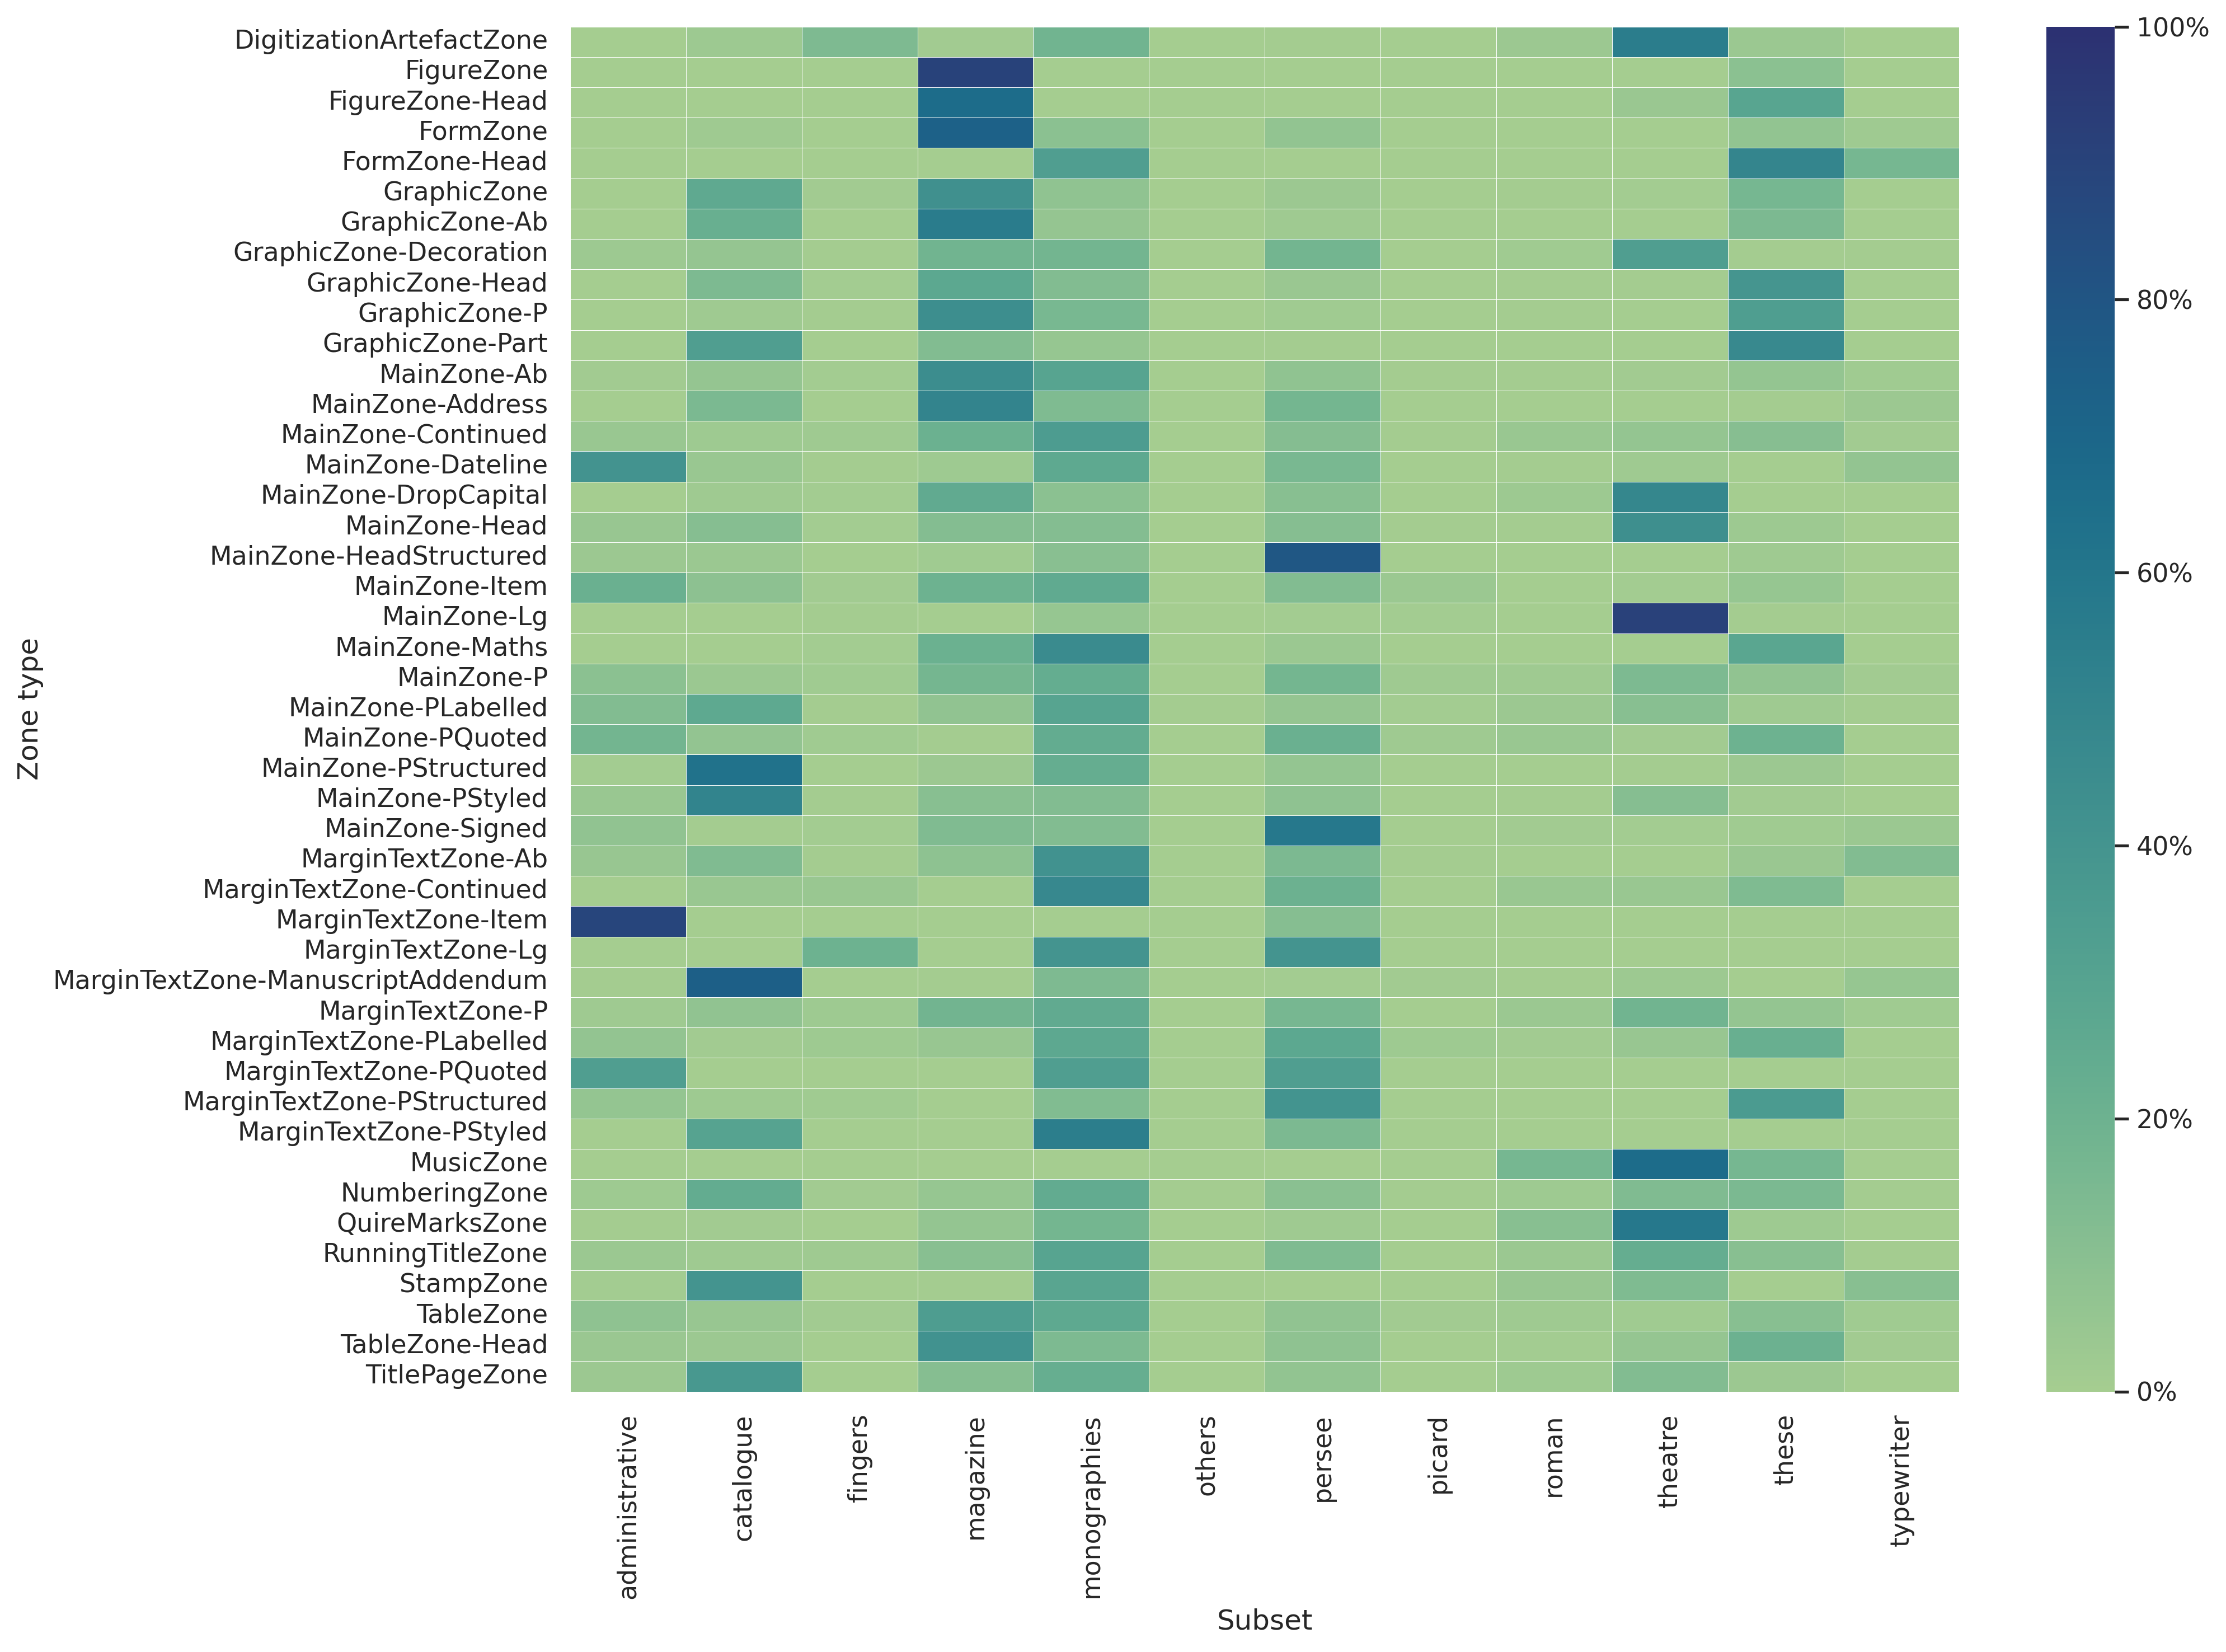

In [23]:
import numpy as np
plt.figure(figsize=(14, 10), dpi=300)
final_norm = final_sorted.div(final_sorted.sum(axis=1) + 1e-9, axis=0)
ax = sns.heatmap(
    final_norm,
    cmap="crest",
    linewidths=0.2,
    fmt=".0%",
    vmin=0, vmax=1,
)
ax.set_xlabel("Subset")
ax.set_ylabel("Zone type")
from matplotlib.ticker import FuncFormatter
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:.0%}")
)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("distribution_zone.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_72904/261032947.py:29: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_labels = final_norm.applymap(lambda x: f"{x:.0%}" if x >= 0.01 else "")


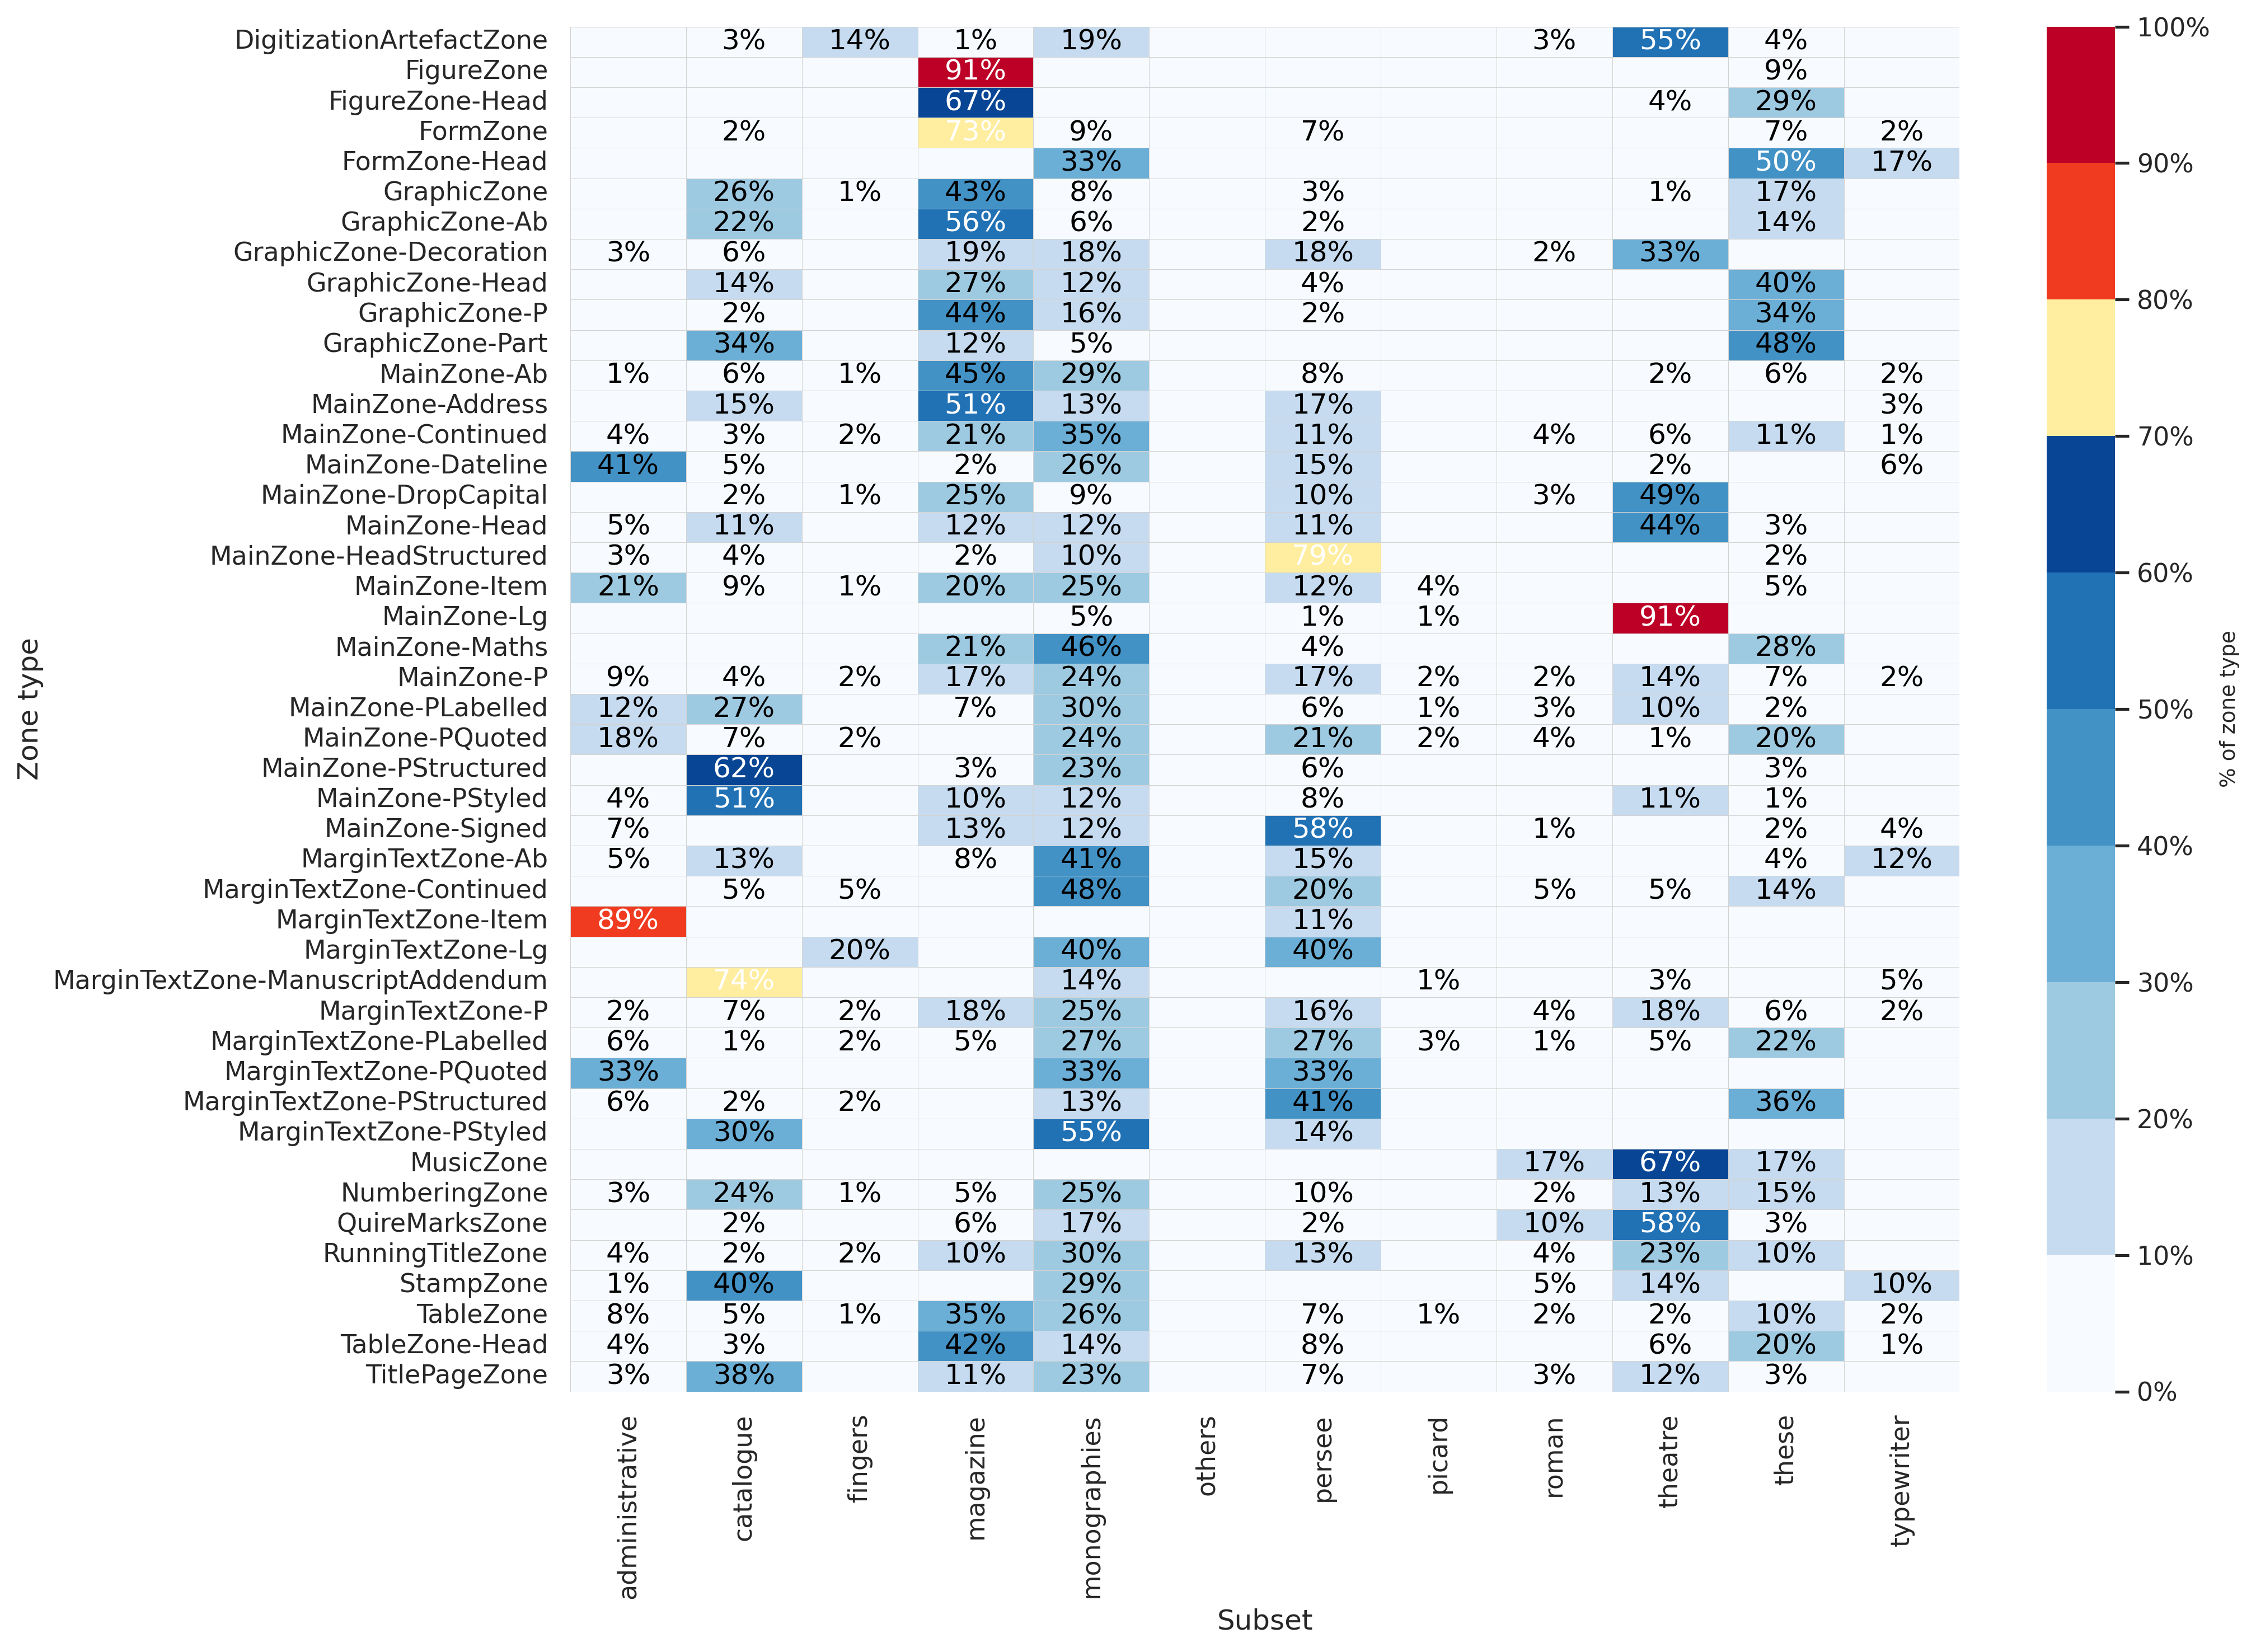

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import FuncFormatter

# --- Row normalization (% per line) ---
final_norm = final_sorted.div(final_sorted.sum(axis=1) + 1e-9, axis=0)

# --- 10 perceptually distinct colors (0% → 100%) ---
colors = [
    "#f7fbff",  # 0–10%   : near white
    "#c6dbef",  # 10–20%  : very light blue
    "#9ecae1",  # 20–30%  : light blue
    "#6baed6",  # 30–40%  : medium blue
    "#4292c6",  # 40–50%  : blue
    "#2171b5",  # 50–60%  : dark blue
    "#084594",  # 60–70%  : very dark blue
    "#ffeda0",  # 70–80%  : light yellow (strong break)
    "#f03b20",  # 80–90%  : orange-red
    "#bd0026",  # 90–100% : deep red
]

boundaries = np.linspace(0, 1, 11)  # [0, 0.1, 0.2, ..., 1.0]
cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries=boundaries, ncolors=len(colors))

# --- Annotations ---
annot_labels = final_norm.applymap(lambda x: f"{x:.0%}" if x >= 0.01 else "")

# --- Plot ---
plt.figure(figsize=(14, 10), dpi=300)
ax = sns.heatmap(
    final_norm,
    annot=annot_labels,
    fmt="",
    cmap=cmap,
    norm=norm,
    linewidths=0.2,
    linecolor="lightgrey",
)

ax.set_xlabel("Subset")
ax.set_ylabel("Zone type")

# --- Auto text color: white on dark cells ---
dark_threshold = 0.5
for text in ax.texts:
    try:
        val = float(text.get_text().replace("%", "")) / 100
        text.set_color("white" if val >= dark_threshold else "black")
    except ValueError:
        pass

# --- Colorbar with one tick per 10% band ---
cbar = ax.collections[0].colorbar
cbar.set_ticks(boundaries)
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
cbar.set_label("% of zone type", fontsize=9)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("distribution_zone.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_72904/1744345070.py:29: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_labels = final_norm.applymap(lambda x: f"{x:.0%}" if x >= 0.01 else "")


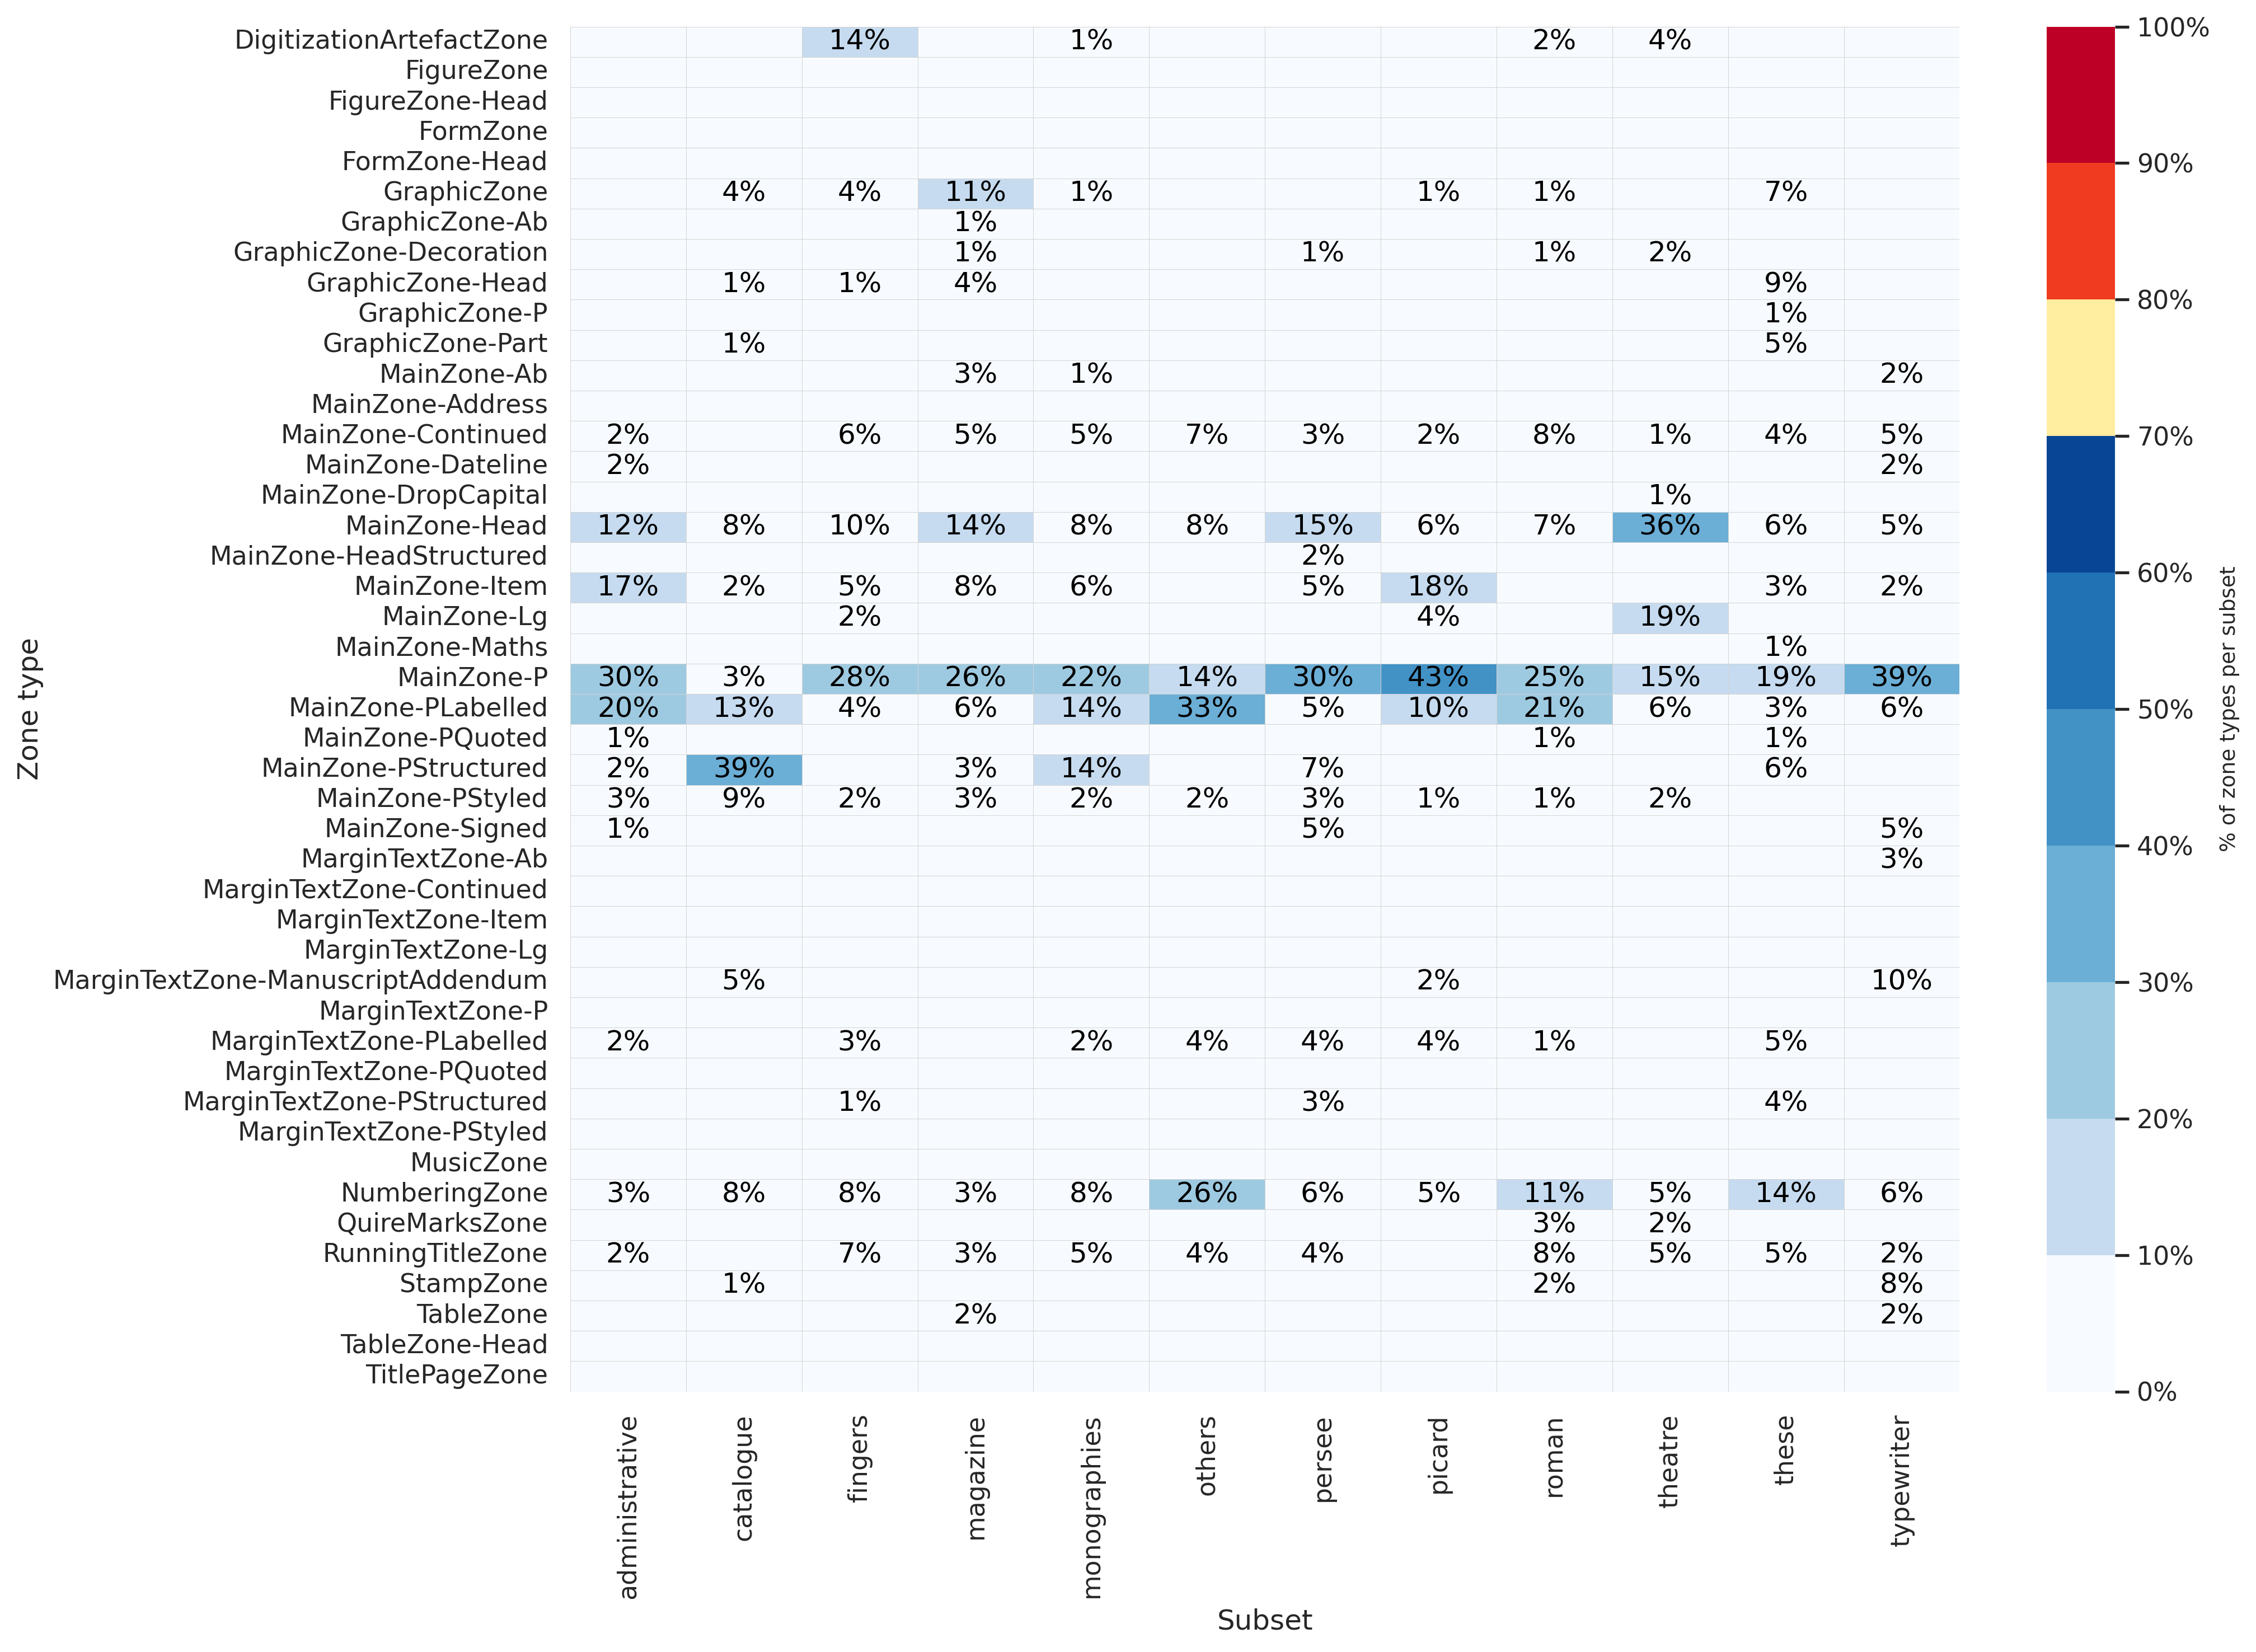

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import FuncFormatter

# --- Column normalization (% of zone types per subset) ---
final_norm = final_sorted.div(final_sorted.sum(axis=0) + 1e-9, axis=1)

# --- 10 perceptually distinct colors ---
colors = [
    "#f7fbff",  # 0–10%   : near white
    "#c6dbef",  # 10–20%  : very light blue
    "#9ecae1",  # 20–30%  : light blue
    "#6baed6",  # 30–40%  : medium blue
    "#4292c6",  # 40–50%  : blue
    "#2171b5",  # 50–60%  : dark blue
    "#084594",  # 60–70%  : very dark blue
    "#ffeda0",  # 70–80%  : light yellow (strong break)
    "#f03b20",  # 80–90%  : orange-red
    "#bd0026",  # 90–100% : deep red
]

boundaries = np.linspace(0, 1, 11)  # [0, 0.1, 0.2, ..., 1.0]
cmap = ListedColormap(colors)
norm = BoundaryNorm(boundaries=boundaries, ncolors=len(colors))

# --- Annotations ---
annot_labels = final_norm.applymap(lambda x: f"{x:.0%}" if x >= 0.01 else "")

# --- Plot ---
plt.figure(figsize=(14, 10), dpi=300)
ax = sns.heatmap(
    final_norm,
    annot=annot_labels,
    fmt="",
    cmap=cmap,
    norm=norm,
    linewidths=0.2,
    linecolor="lightgrey",
)

ax.set_xlabel("Subset")
ax.set_ylabel("Zone type")

# --- Auto text color: white on dark cells ---
for text in ax.texts:
    try:
        val = float(text.get_text().replace("%", "")) / 100
        text.set_color("white" if val >= 0.5 else "black")
    except ValueError:
        pass

# --- Colorbar ---
cbar = ax.collections[0].colorbar
cbar.set_ticks(boundaries)
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
cbar.set_label("% of zone types per subset", fontsize=9)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("distribution_zone.png", dpi=300, bbox_inches="tight")
plt.show()

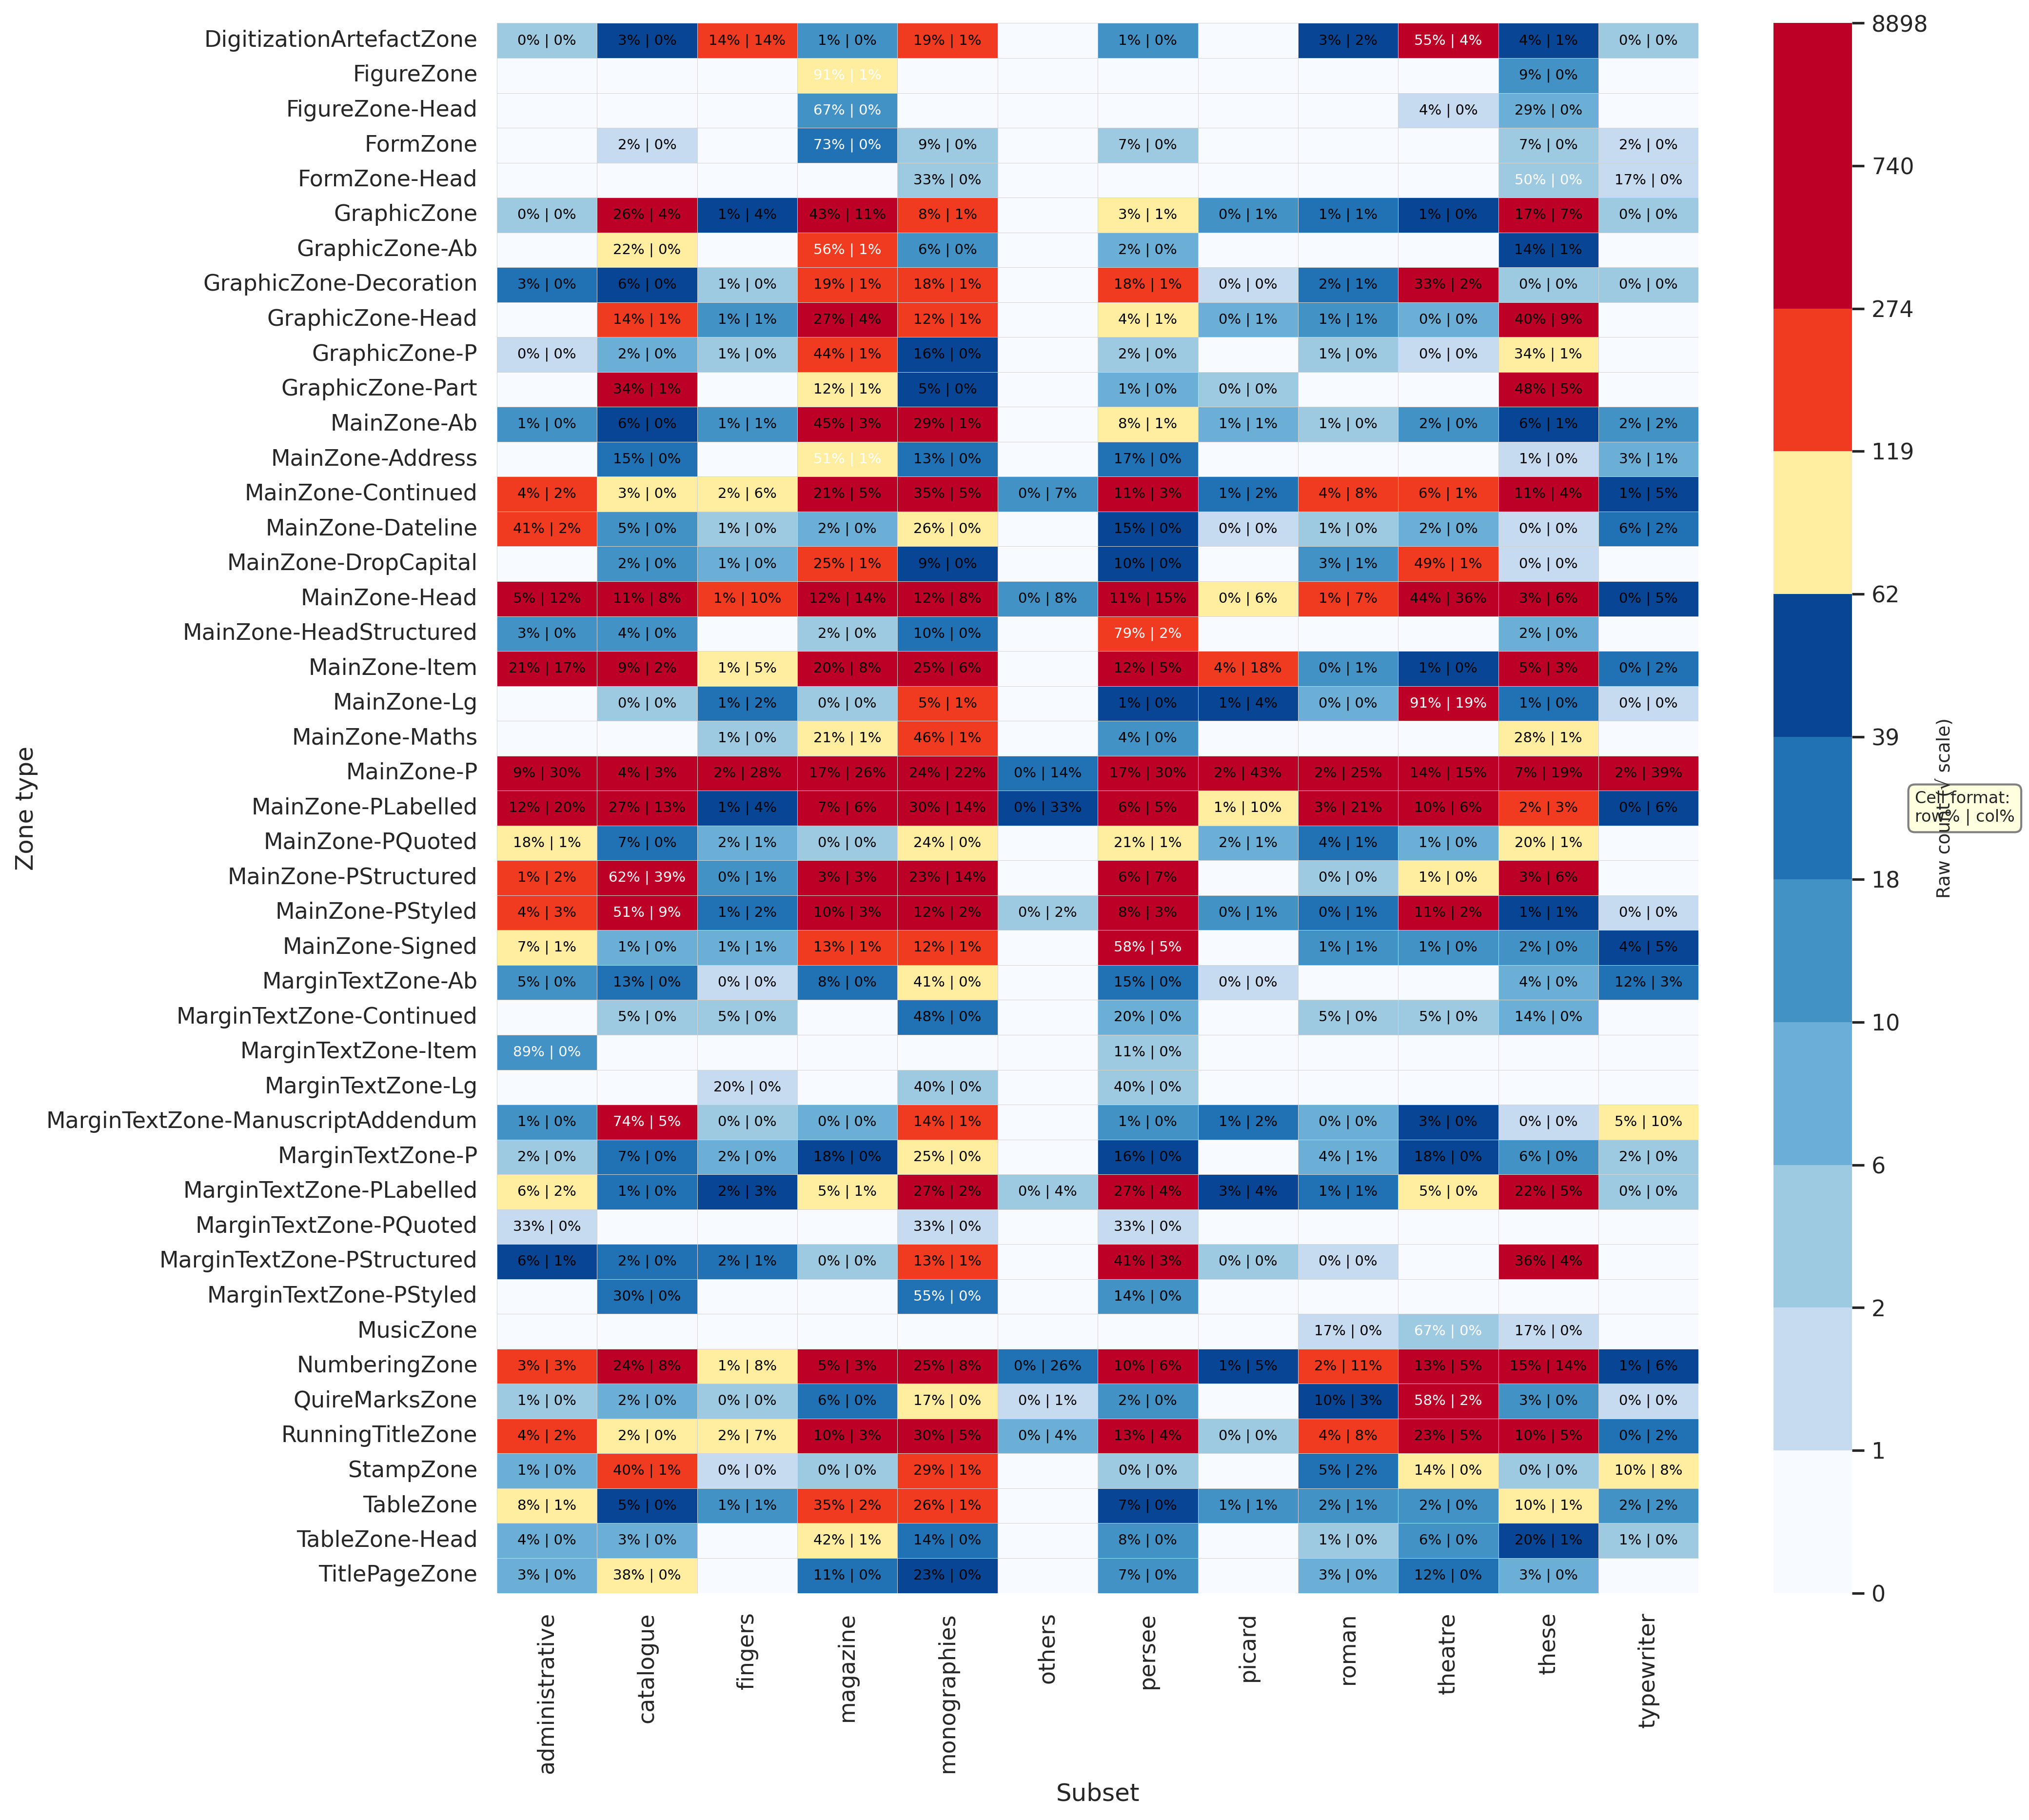

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import FuncFormatter

# --- Filter empty rows ---
final_filtered = final_sorted[final_sorted.sum(axis=1) > 0]

# --- Both normalizations for annotations ---
norm_row = final_filtered.div(final_filtered.sum(axis=1) + 1e-9, axis=0)
norm_col = final_filtered.div(final_filtered.sum(axis=0) + 1e-9, axis=1)

# --- Annotations: row% | col% ---
annot_labels = np.empty(final_filtered.shape, dtype=object)
for i in range(final_filtered.shape[0]):
    for j in range(final_filtered.shape[1]):
        raw = int(final_filtered.iloc[i, j])
        r = norm_row.iloc[i, j]
        c = norm_col.iloc[i, j]
        annot_labels[i, j] = f"{r:.0%} | {c:.0%}" if raw > 0 else ""

# --- Square root transform for color (compresses skew, stays intuitive) ---
data_sqrt = np.sqrt(final_filtered)

# --- Quantile boundaries on sqrt-transformed non-zero values ---
flat_nonzero = data_sqrt.values.flatten()
flat_nonzero = flat_nonzero[flat_nonzero > 0]
boundaries = np.nanquantile(flat_nonzero, np.linspace(0, 1, 11))
boundaries = np.unique(np.concatenate([[0], boundaries]))

# --- 10 perceptually distinct colors ---
colors = [
    "#f7fbff",
    "#c6dbef",
    "#9ecae1",
    "#6baed6",
    "#4292c6",
    "#2171b5",
    "#084594",
    "#ffeda0",
    "#f03b20",
    "#bd0026",
]

n_bands = len(boundaries) - 1
cmap = ListedColormap(colors[:n_bands])
norm = BoundaryNorm(boundaries=boundaries, ncolors=n_bands)

# --- Plot ---
plt.figure(figsize=(14, max(8, len(final_filtered) * 0.28)), dpi=300)
ax = sns.heatmap(
    data_sqrt,
    annot=annot_labels,
    fmt="",
    cmap=cmap,
    norm=norm,
    linewidths=0.2,
    linecolor="lightgrey",
    annot_kws={"size": 7},
)

ax.set_xlabel("Subset")
ax.set_ylabel("Zone type")

# --- Annotation legend ---
ax.text(
    1.18, 0.5,
    "Cell format:\nrow% | col%",
    transform=ax.transAxes,
    fontsize=8,
    va="center",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow", edgecolor="grey")
)

# --- Auto text color ---
for text in ax.texts:
    try:
        first_pct = float(text.get_text().split("|")[0].replace("%", "").strip()) / 100
        text.set_color("white" if first_pct >= 0.5 else "black")
    except (ValueError, IndexError):
        pass

# --- Colorbar: show REAL counts at tick positions (not sqrt values) ---
cbar = ax.collections[0].colorbar
real_ticks = boundaries ** 2  # convert back to original scale
cbar.set_ticks(boundaries)
cbar.ax.set_yticklabels([f"{v:.0f}" for v in real_ticks])
cbar.set_label("Raw count (√ scale)", fontsize=9)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("distribution_zone.png", dpi=300, bbox_inches="tight")
plt.show()

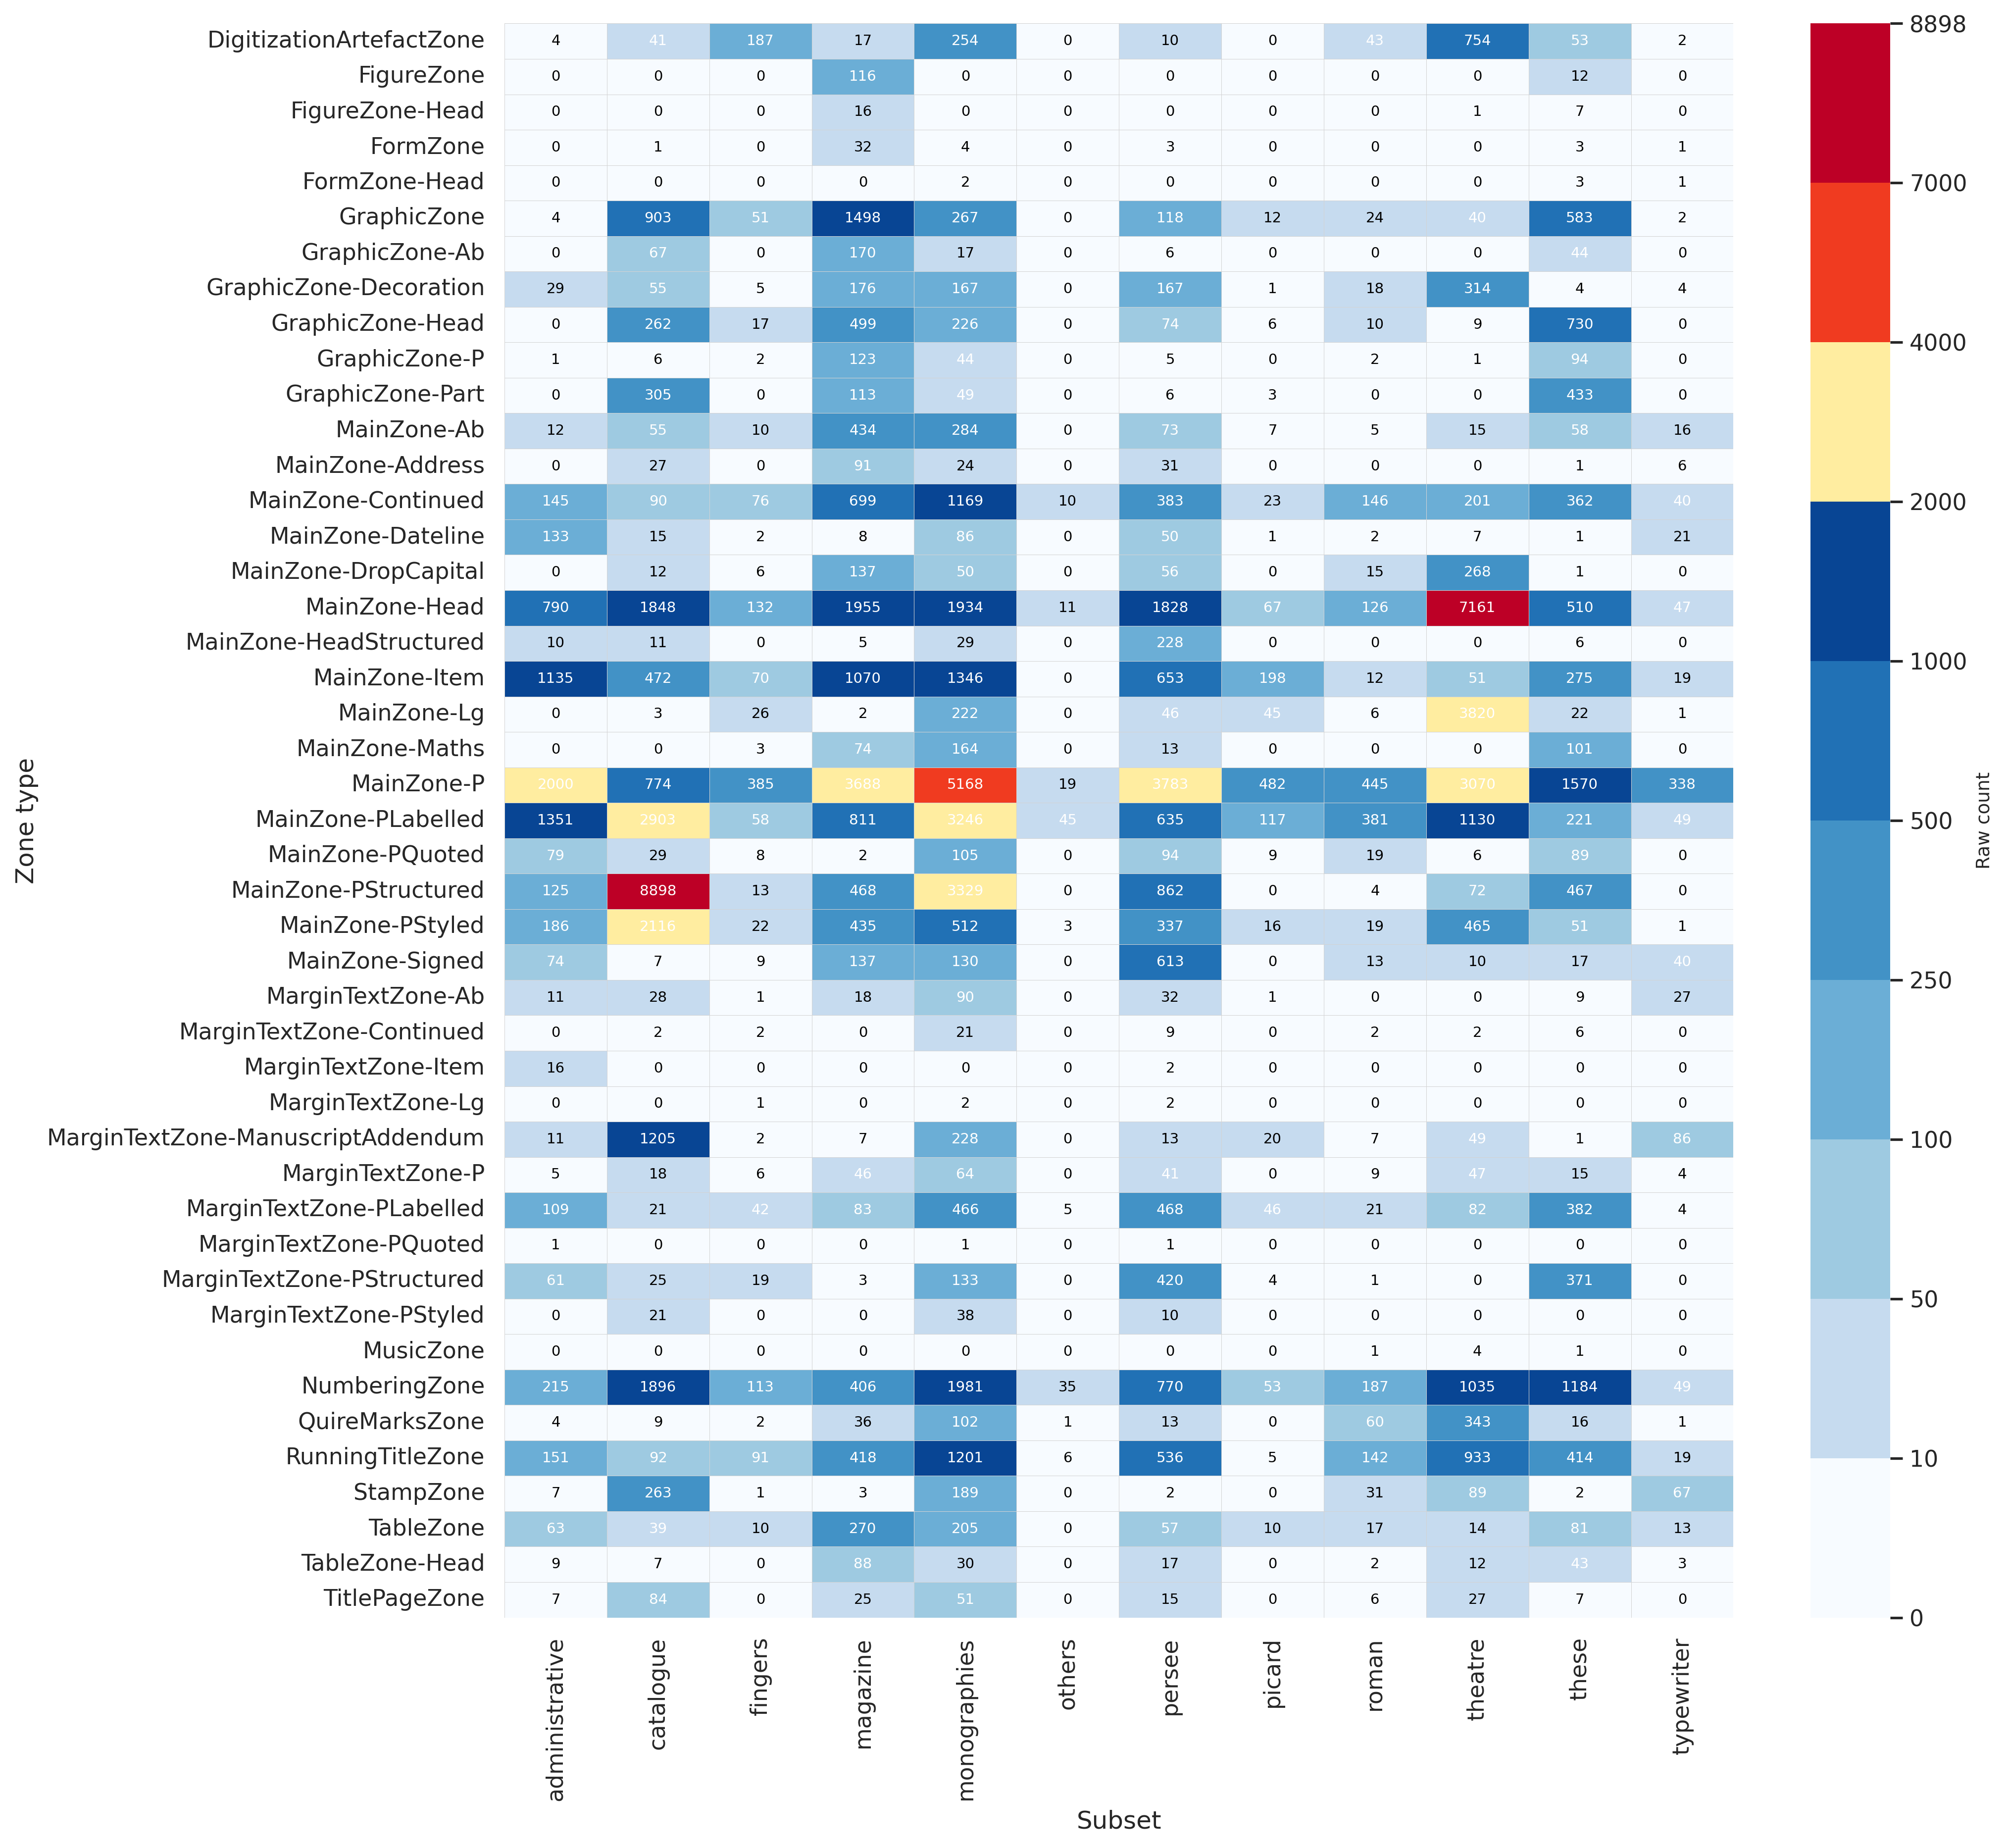

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, BoundaryNorm

# --- Filter empty rows ---
final_filtered = final_sorted[final_sorted.sum(axis=1) > 0]

vmax = int(final_filtered.values.max())

boundaries = np.array([0, 10, 50, 100, 250, 500, 1000, 2000, 4000, 7000, vmax])
boundaries = np.unique(boundaries)  # remove duplicates if vmax overlaps

# --- 10 perceptually distinct colors ---
colors = [
    "#f7fbff",
    "#c6dbef",
    "#9ecae1",
    "#6baed6",
    "#4292c6",
    "#2171b5",
    "#084594",
    "#ffeda0",
    "#f03b20",
    "#bd0026",
]

n_bands = len(boundaries) - 1
cmap = ListedColormap(colors[:n_bands])
norm = BoundaryNorm(boundaries=boundaries, ncolors=n_bands)

# --- Plot ---
plt.figure(figsize=(14, max(8, len(final_filtered) * 0.28)), dpi=300)
ax = sns.heatmap(
    final_filtered,
    annot=True,
    fmt=".0f",
    cmap=cmap,
    norm=norm,
    linewidths=0.2,
    linecolor="lightgrey",
    annot_kws={"size": 7},
)

ax.set_xlabel("Subset")
ax.set_ylabel("Zone type")

# --- Auto text color ---
for text in ax.texts:
    try:
        val = float(text.get_text())
        threshold = np.nanquantile(flat_nonzero, 0.5)
        text.set_color("white" if val >= threshold else "black")
    except ValueError:
        pass

# --- Colorbar ---
cbar = ax.collections[0].colorbar
cbar.set_ticks(boundaries)
cbar.ax.set_yticklabels([f"{v:.0f}" for v in boundaries])
cbar.set_label("Raw count", fontsize=9)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("distribution_zone.png", dpi=300, bbox_inches="tight")
plt.show()